# HW03：NumPy、Matplotlib 与 pandas

学号：20244080115　姓名：胡勇彦

In [1]:
import hashlib
import os
import platform
import uuid

STUDENT_ID = 20244080115

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] base
[学号] 20244080115
[机器指纹] c27f93f8bd6c2a0d
[RUN_ID] 20244080115-c27f93f8bd6c2a0d


## 一、围绕半圆定律

### 1. `wigner_density(x)`：半圆密度，使用 `numpy.sqrt`，标量与数组均适用

In [2]:
import numpy as np

def wigner_density(x):
    arr = np.asarray(x, dtype=float)
    vals = np.where(
        np.abs(arr) <= 2,
        np.sqrt(np.maximum(4 - arr ** 2, 0)) / (2 * np.pi),
        0.0,
    )
    return float(vals) if vals.ndim == 0 else vals

print(wigner_density(0))
print(wigner_density(2))
print(wigner_density(3))
print(wigner_density(np.array([-2, -1, 0, 1, 2, 3])))

0.3183098861837907
0.0
0.0
[0.         0.27566445 0.31830989 0.27566445 0.         0.        ]


### 2. `generate_wigner(n)`：生成 Wigner 对称矩阵，非法输入抛异常

In [3]:
def generate_wigner(n):
    if isinstance(n, bool) or not isinstance(n, int) or n <= 0:
        raise ValueError("n must be a positive integer")
    a = np.random.normal(scale=1.0 / np.sqrt(n), size=(n, n))
    z = np.triu(a) + np.triu(a, k=1).T   # 对角线只取一次，矩阵对称
    return z

np.random.seed(42)
z = generate_wigner(5)
print(z)
print("对称:", np.allclose(z, z.T))
try:
    generate_wigner(-3)
except ValueError as e:
    print("ValueError:", e)

[[ 0.22213732 -0.06183368  0.28965512  0.68111966 -0.10471657]
 [-0.06183368  0.70624544  0.34320724 -0.20995533  0.24264023]
 [ 0.28965512  0.34320724  0.10820882 -0.85564494 -0.77140671]
 [ 0.68111966 -0.20995533 -0.85564494 -0.40608071 -0.63160142]
 [-0.10471657  0.24264023 -0.77140671 -0.63160142 -0.24345536]]
对称: True
ValueError: n must be a positive integer


### 3. `get_spectrum(matrix)`：返回非递减排列的特征值

In [4]:
def get_spectrum(matrix):
    eig = np.linalg.eigvalsh(matrix)
    return np.sort(eig)

sp = get_spectrum(generate_wigner(50))
print(sp[:5], "...", sp[-5:])
print("非递减:", np.all(np.diff(sp) >= 0))

[-1.77458145 -1.65675456 -1.61889597 -1.49910392 -1.45800142] ... [1.38402002 1.4185482  1.5528098  1.68022731 2.00952637]
非递减: True


### 4. 四个纵向子图：标准化直方图 + 红色半圆密度曲线

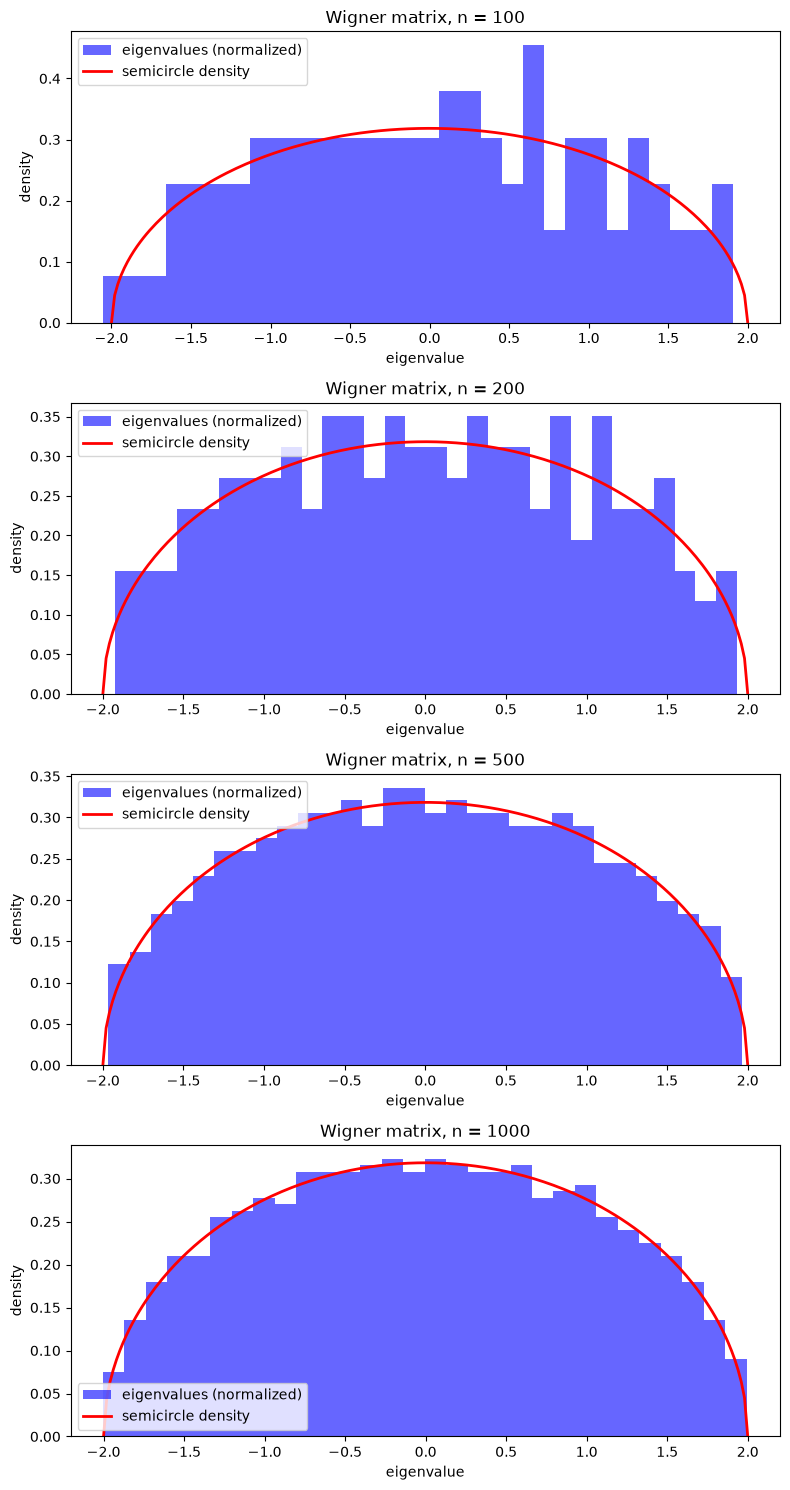

In [5]:
import matplotlib.pyplot as plt

np.random.seed(42)
ns = [100, 200, 500, 1000]
xgrid = np.linspace(-2, 2, 200)
fig, axes = plt.subplots(4, 1, figsize=(8, 15))

for ax, n in zip(axes, ns):
    spectrum = get_spectrum(generate_wigner(n))
    ax.hist(spectrum, bins=30, density=True, color="blue", alpha=0.6,
            label="eigenvalues (normalized)")
    ax.plot(xgrid, wigner_density(xgrid), "r-", linewidth=2,
            label="semicircle density")
    ax.set_title(f"Wigner matrix, n = {n}")
    ax.set_xlabel("eigenvalue")
    ax.set_ylabel("density")
    ax.legend()

plt.tight_layout()
plt.show()

**结论：** 随 `n` 增大，特征值直方图逐渐贴合红色半圆密度曲线。`n = 100` 时还有明显波动和边缘偏差；`n ≈ 500` 时已能较好拟合；`n = 1000` 时直方图与密度曲线几乎重合，拟合效果很好。因此 `n` 大约达到 **500** 时半圆密度就能较好地拟合特征值分布，`1000` 时拟合非常好。

## 二、Conway 的生命游戏

### 1. `is_valid_board`：二维且元素仅为 0/1

In [6]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray) or board.ndim != 2:
        return False
    return bool(np.all((board == 0) | (board == 1)))

b = np.array([[0, 1], [1, 0]])
print(is_valid_board(b))
print(is_valid_board(np.array([[0, 2], [1, 0]])))
print(is_valid_board(np.array([0, 1, 1])))

True
False
False


### 2. `gol_step`：环绕边界，用 `np.roll` 统计八个邻居，基于原棋盘同时更新

In [7]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("invalid board")
    neighbors = np.zeros(board.shape, dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)
    new_board = np.zeros(board.shape, dtype=board.dtype)
    new_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    new_board[(board == 0) & (neighbors == 3)] = 1
    return new_board

# 滑翔机（glider）测试，含环绕边界
glider = np.zeros((6, 6), dtype=int)
glider[0, 1] = glider[1, 2] = glider[2, 0] = glider[2, 1] = glider[2, 2] = 1
print(glider)
print("->")
print(gol_step(glider))
try:
    gol_step(np.array([[0, 2]]))
except ValueError as e:
    print("ValueError:", e)

[[0 1 0 0 0 0]
 [0 0 1 0 0 0]
 [1 1 1 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]
->
[[0 0 0 0 0 0]
 [1 0 1 0 0 0]
 [0 1 1 0 0 0]
 [0 1 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]
ValueError: invalid board


### 3. `draw_gol_board`：活细胞黑色、死细胞白色，无网格线/轴标签/刻度

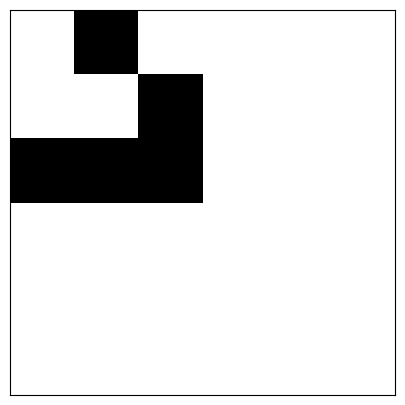

In [8]:
def draw_gol_board(board):
    plt.figure(figsize=(5, 5))
    plt.imshow(board, cmap=plt.get_cmap("binary"), interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.show()

draw_gol_board(glider)

## 三、使用 pandas DataFrame

### 1. 读入 `iris.csv` 并回答基本信息

In [9]:
import pandas as pd

df = pd.read_csv("iris.csv")
print("数据点数量:", len(df))
print("列名:", list(df.columns))
print("各列数据类型:")
print(df.dtypes)
print("花卉种类:", df["species"].unique())
print("花卉种类数:", df["species"].nunique())
df.head()

数据点数量: 150
列名: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
各列数据类型:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object
花卉种类: <ArrowStringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
花卉种类数: 3


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 2. 修正第 35 行（索引 34）和第 38 行（索引 37）

In [10]:
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]
print(df.loc[[34, 37]])

    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.2  setosa
37           4.9          3.6           1.4          0.1  setosa


### 3. 添加 `Petal.Ratio` 与 `Sepal.Ratio`

In [11]:
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]
print(df.head())

   sepal_length  sepal_width  petal_length  petal_width species  Petal.Ratio  \
0           5.1          3.5           1.4          0.2  setosa          7.0   
1           4.9          3.0           1.4          0.2  setosa          7.0   
2           4.7          3.2           1.3          0.2  setosa          6.5   
3           4.6          3.1           1.5          0.2  setosa          7.5   
4           5.0          3.6           1.4          0.2  setosa          7.0   

   Sepal.Ratio  
0     1.457143  
1     1.633333  
2     1.468750  
3     1.483871  
4     1.388889  


### 4. 保存为 `iris_corrected.csv`

In [12]:
df.to_csv("iris_corrected.csv", index=False)
check = pd.read_csv("iris_corrected.csv")
print(check.shape)
print(list(check.columns))

(150, 7)
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species', 'Petal.Ratio', 'Sepal.Ratio']


### 5. 按花卉种类分组，对两个 Ratio 计算均值、中位数、最小值、最大值、标准差

In [13]:
summary = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print(summary)

           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species                                             
setosa      1.463063  1.268293  1.956522  0.118750  
versicolor  2.161290  1.764706  2.818182  0.228658  
virginica   2.169540  1.823529  2.961538  0.246992  
